# Classificador de Máxima Correlação

*Implementação com scikit-learn · base original (sem pré-processamento)*

Cada classe é representada pelo seu centroide $\mathbf{m}_i$. A amostra é atribuída à classe de maior correlação (cosseno do ângulo) com ela:

$$\hat{y}(\mathbf{x}) = \arg\max_i \frac{\mathbf{x}^\top \mathbf{m}_i}{\|\mathbf{x}\|\,\|\mathbf{m}_i\|}$$

Como $\|\mathbf{x}\|$ é o mesmo para todas as classes, basta normalizar os centroides.

Protocolo (OBS 1–4 do enunciado): 100 rodadas treino-teste independentes e estratificadas para cada separação 20/80, 30/70, 50/50, 70/30 e 80/20.

## Dados

In [1]:
import os
os.environ["OPENBLAS_NUM_THREADS"] = "1"  # antes do numpy: evita falta de memória do OpenBLAS no Windows

import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
from avaliacao import (SPLITS, carregar, avaliar, estatisticas, matrizes_confusao, grafico_splits,
                       por_classe, grafico_por_classe, resumo, salvar)

pd.set_option("display.max_rows", 200)

X, y, classes = carregar(processada=False)
print(f"{len(y)} instâncias | {X.shape[1]} atributos | {len(classes)} classes: {list(classes)}")

5456 instâncias | 4 atributos | 4 classes: ['Move-Forward', 'Sharp-Right-Turn', 'Slight-Left-Turn', 'Slight-Right-Turn']


## Modelo

In [2]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.neighbors import NearestCentroid


class MaximaCorrelacao(ClassifierMixin, BaseEstimator):
    """O scikit-learn não possui este classificador: reaproveita os centroides do NearestCentroid."""

    def fit(self, X, y):
        nc = NearestCentroid().fit(X, y)
        self.classes_ = nc.classes_
        self.prototipos_ = nc.centroids_ / np.linalg.norm(nc.centroids_, axis=1, keepdims=True)
        return self

    def predict(self, X):
        return self.classes_[(X @ self.prototipos_.T).argmax(axis=1)]  # maior cosseno


MODELOS = {"Máxima correlação": MaximaCorrelacao()}

## Execução
100 rodadas × 5 separações. Em cada rodada, todos os modelos usam a mesma divisão treino/teste.

In [3]:
res, confusoes = avaliar(MODELOS, X, y, classes)
salvar(res, "classification_sklearn_raw", "max_correlacao")

## OBS 1 e 2 — Estatísticas de acurácia e tempos de treinamento/teste (ms)

In [4]:
estatisticas(res).round(4)

,,média,desvio,máxima,mínima,mediana,t_treino_ms,t_teste_ms
split,modelo,,,,,,,
20/80,Máxima correlação,0.5775,0.0237,0.6525,0.5230,0.5775,2.7968,0.3312
30/70,Máxima correlação,0.5789,0.0223,0.6661,0.5391,0.5744,2.8291,0.2892
50/50,Máxima correlação,0.5732,0.0125,0.6057,0.5401,0.5724,3.4001,0.2347
70/30,Máxima correlação,0.5726,0.0115,0.6021,0.5397,0.5718,3.1738,0.1616
80/20,Máxima correlação,0.5700,0.0119,0.6004,0.5445,0.5697,3.2582,0.1578


## OBS 2 — Matrizes de confusão da melhor e da pior rodada

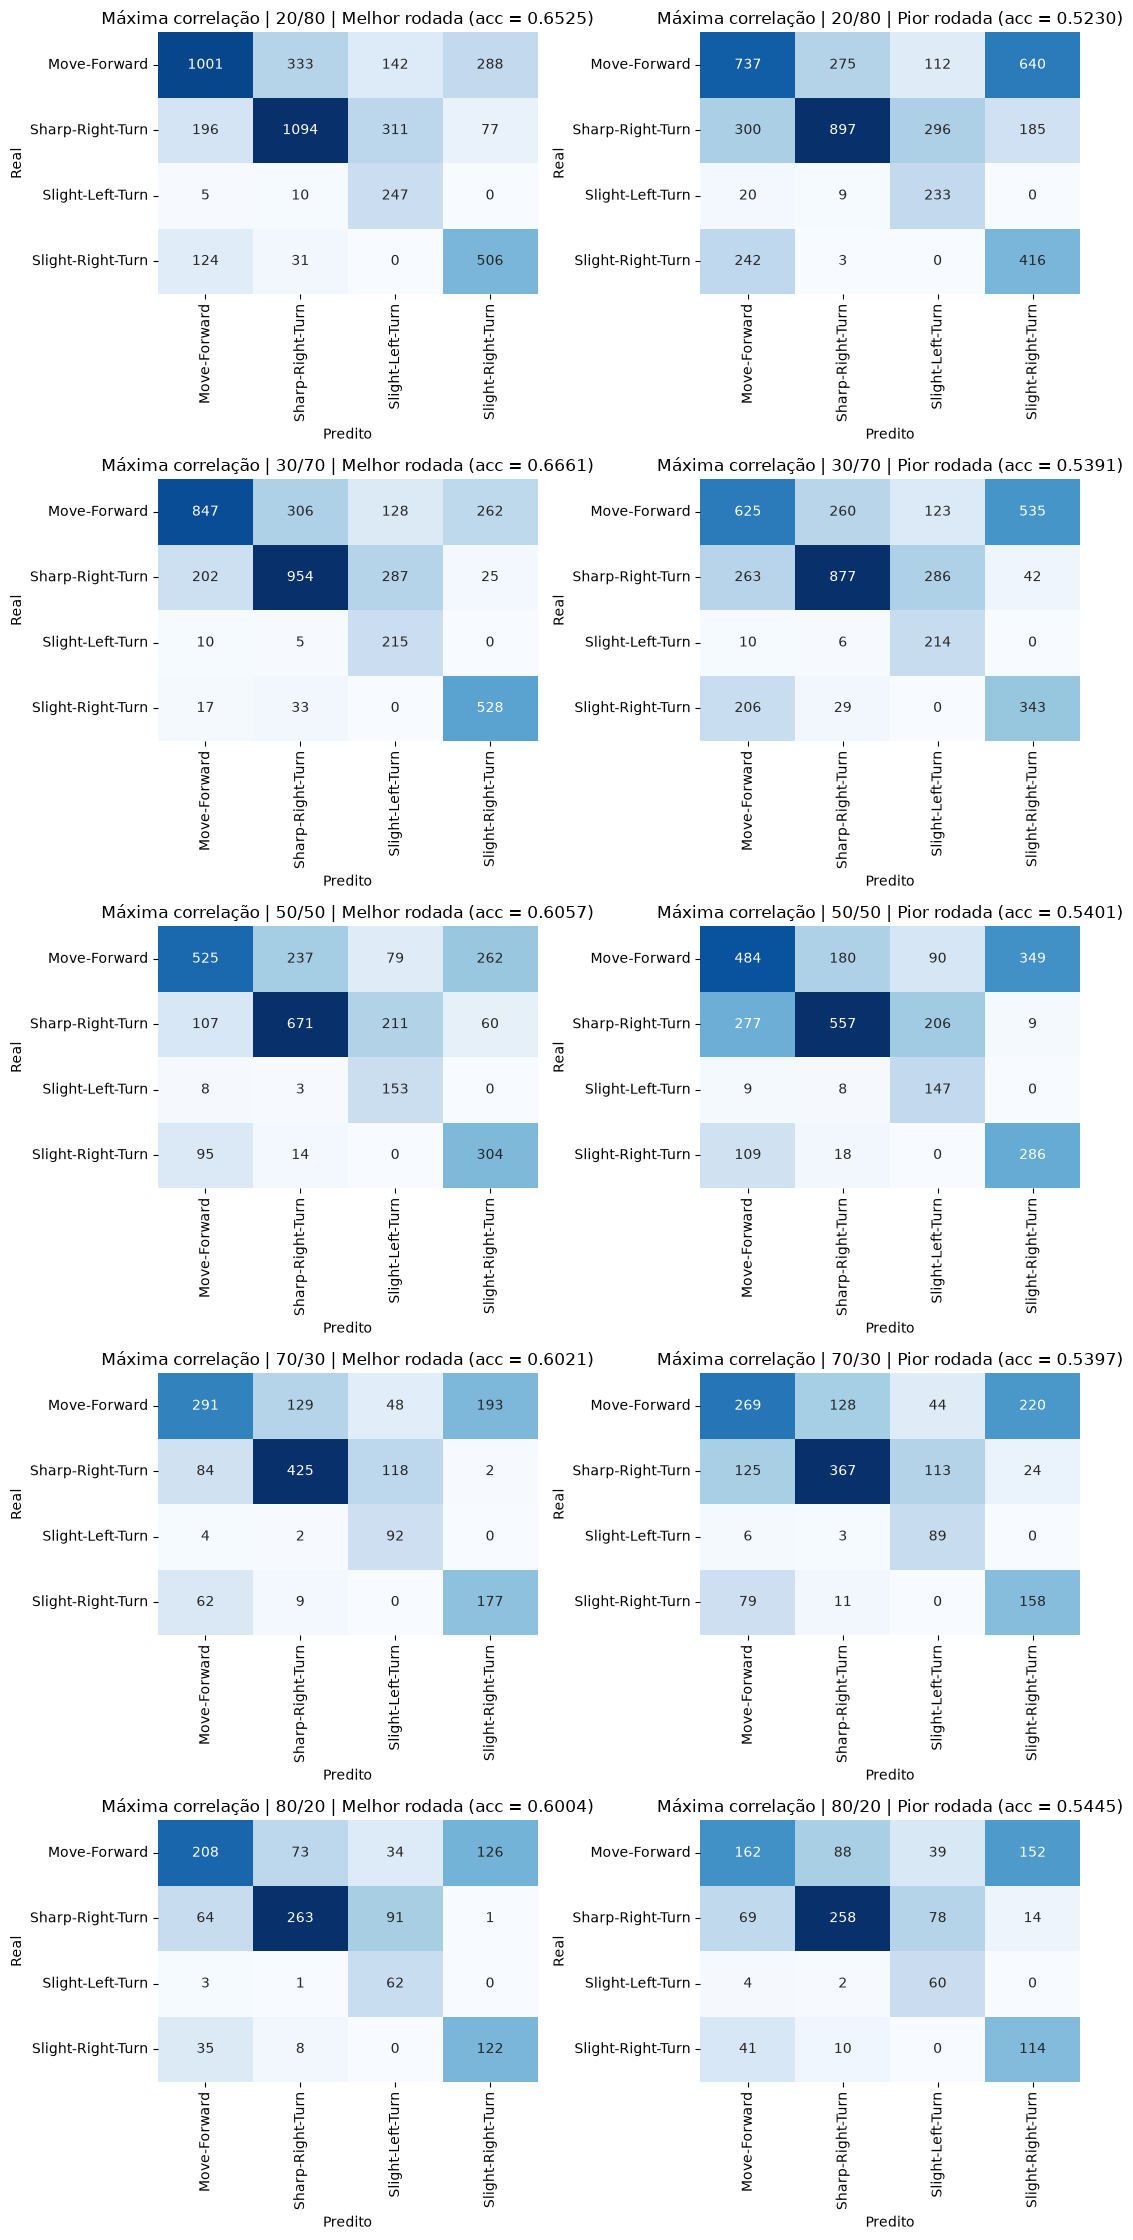

In [5]:
matrizes_confusao(res, confusoes, classes, splits=SPLITS)

## OBS 3 — Efeito da separação treino/teste

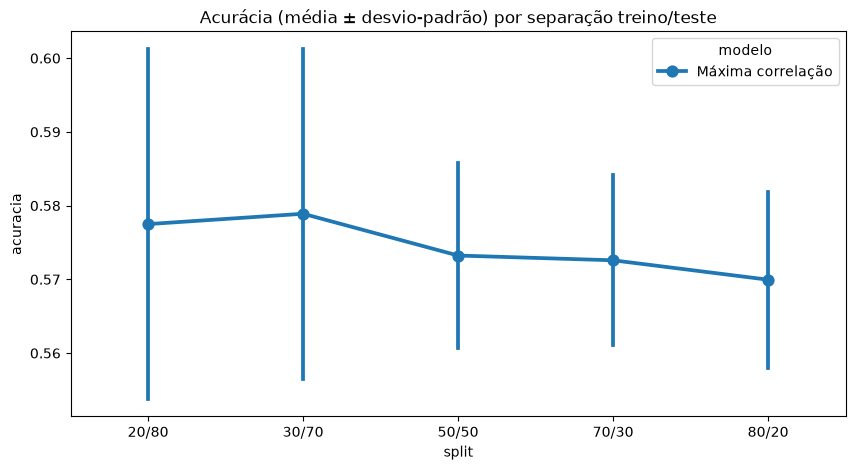

In [6]:
grafico_splits(res)

## OBS 4 — Desempenho por classe (taxa de acerto de cada classe)

In [7]:
por_classe(res, classes).round(4)

média  desvio  máxima  mínima  \
classe            split modelo                                              
Move-Forward      20/80 Máxima correlação  0.4442  0.0407  0.5675  0.3872   
                  30/70 Máxima correlação  0.4341  0.0357  0.5489  0.3837   
                  50/50 Máxima correlação  0.4217  0.0173  0.4760  0.3853   
                  70/30 Máxima correlação  0.4181  0.0168  0.4781  0.3737   
                  80/20 Máxima correlação  0.4139  0.0224  0.4717  0.3628   
Sharp-Right-Turn  20/80 Máxima correlação  0.6210  0.0329  0.6669  0.5191   
                  30/70 Máxima correlação  0.6292  0.0212  0.6649  0.5484   
                  50/50 Máxima correlação  0.6300  0.0171  0.6654  0.5310   
                  70/30 Máxima correlação  0.6324  0.0175  0.6773  0.5835   
                  80/20 Máxima correlação  0.6306  0.0165  0.6706  0.5990   
Slight-Left-Turn  20/80 Máxima correlação  0.9260  0.0156  0.9504  0.8817   
                  30/70 Máxima correlação  0.9296  0.0142  0.9609  0.8696   
                  50/50 Máxima correlação  0.9287  0.0158  0.9878  0.8841   
                  70/30 Máxima correlação  0.9268  0.0215  0.9796  0.8571   
                  80/20 Máxima correlação  0.9268  0.0269  0.9848  0.8485   
Slight-Right-Turn 20/80 Máxima correlação  0.6848  0.0658  0.8472  0.5174   
                  30/70 Máxima correlação  0.6982  0.0655  0.9135  0.5311   
                  50/50 Máxima correlação  0.6926  0.0356  0.7942  0.5981   
                  70/30 Máxima correlação  0.6926  0.0305  0.7621  0.6089   
                  80/20 Máxima correlação  0.6904  0.0366  0.7758  0.6182   

                                           mediana  
classe            split modelo                      
Move-Forward      20/80 Máxima correlação   0.4379  
                  30/70 Máxima correlação   0.4206  
                  50/50 Máxima correlação   0.4202  
                  70/30 Máxima correlação   0.4191  
                  80/20 Máxima correlação   0.4150  
Sharp-Right-Turn  20/80 Máxima correlação   0.6278  
                  30/70 Máxima correlação   0.6322  
                  50/50 Máxima correlação   0.6296  
                  70/30 Máxima correlação   0.6328  
                  80/20 Máxima correlação   0.6277  
Slight-Left-Turn  20/80 Máxima correlação   0.9313  
                  30/70 Máxima correlação   0.9304  
                  50/50 Máxima correlação   0.9268  
                  70/30 Máxima correlação   0.9286  
                  80/20 Máxima correlação   0.9242  
Slight-Right-Turn 20/80 Máxima correlação   0.6876  
                  30/70 Máxima correlação   0.6972  
                  50/50 Máxima correlação   0.6925  
                  70/30 Máxima correlação   0.6915  
                  80/20 Máxima correlação   0.6909

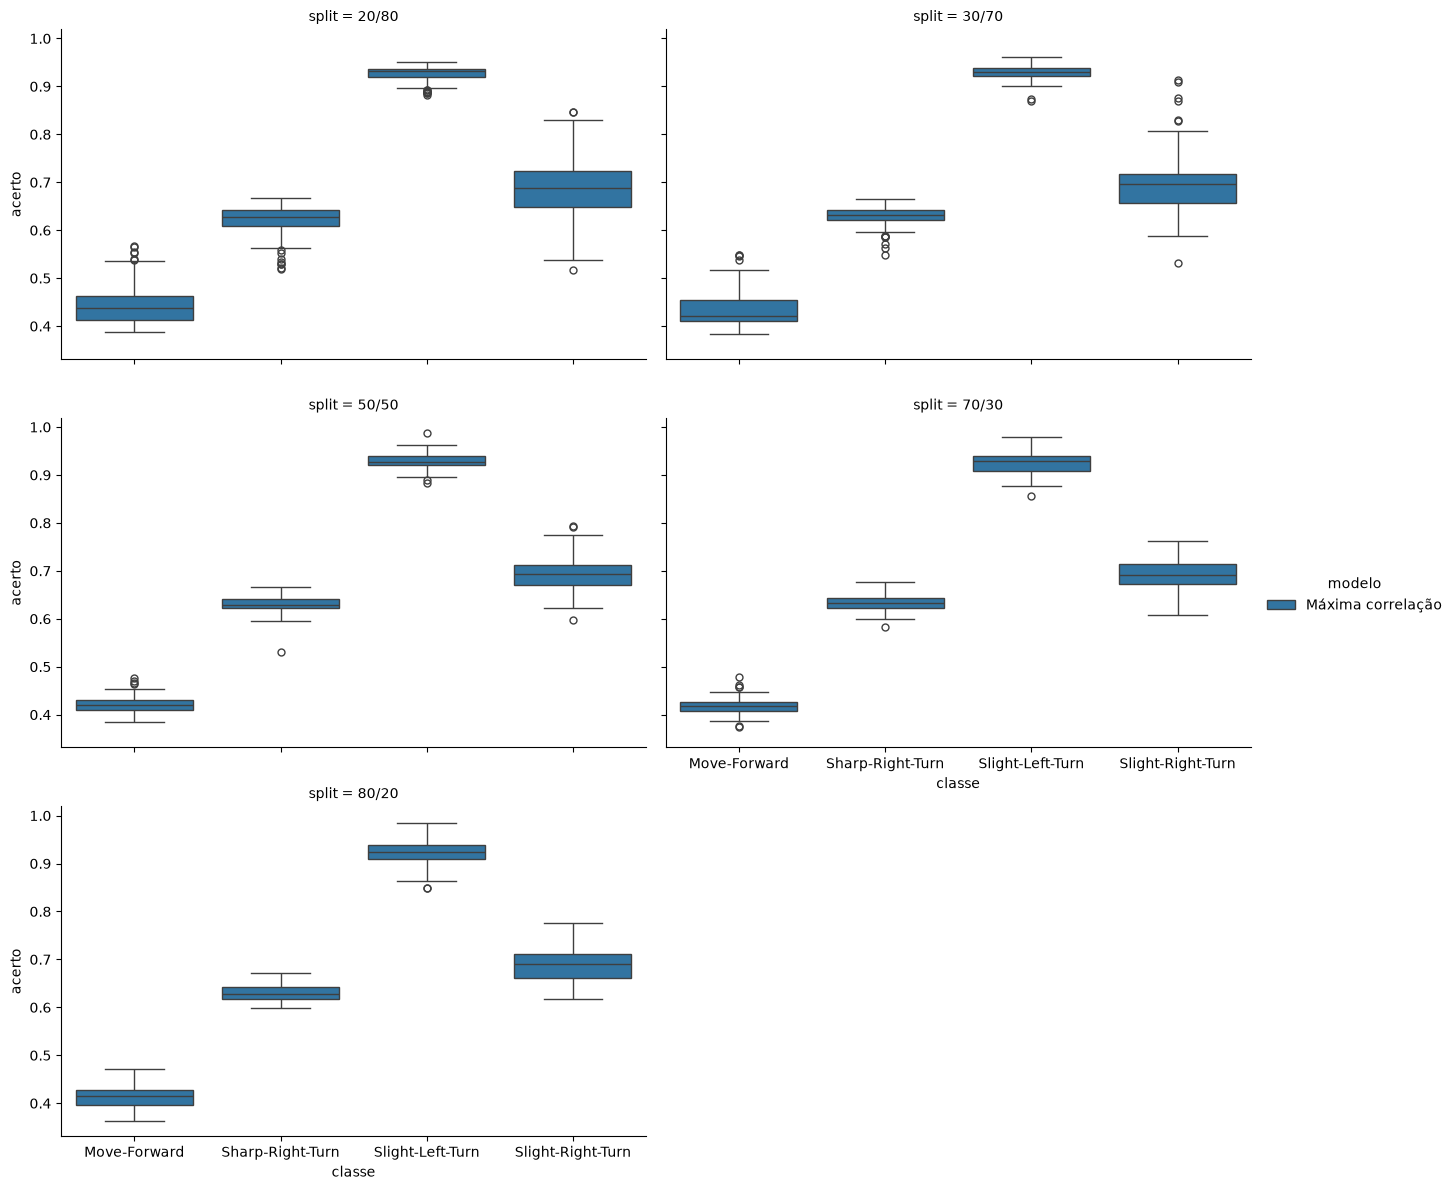

In [8]:
grafico_por_classe(res, classes)

## Resumo dos resultados

In [9]:
resumo(res, classes)

Melhor configuração: Máxima correlação com split 30/70 -> acurácia média 0.5789

Tempo médio por rodada (ms):
  Máxima correlação: treino 3.092 | teste 0.235

Efeito do split (acurácia média 20/80 -> 80/20):
  Máxima correlação: 0.5775 -> 0.5700 (-0.0075)

Taxa de acerto média por classe (todas as rodadas):
  Move-Forward: 0.4264
  Sharp-Right-Turn: 0.6286
  Slight-Right-Turn: 0.6917
  Slight-Left-Turn: 0.9276
Classe mais fácil: Slight-Left-Turn | mais difícil: Move-Forward
